# PORTFÓLIO — Tarefa 2
## Segmentação semântica e segmentação por instância

A segmentação semântica identifica os pixels pertencentes ao primeiro plano, atribuindo a mesma classe a todos os objetos. A segmentação por instância, além de identificar o primeiro plano, atribui um rótulo diferente para cada objeto encontrado.

Neste notebook, a comparação será feita com uma imagem de moedas e com outra imagem gerada pela biblioteca skimage.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage as ndi
from skimage import color, data, feature, filters, measure, morphology, segmentation, util

In [ ]:
def mostrar(imagens, titulos, cmaps=None, tamanho=5):
    if cmaps is None:
        cmaps = ['gray'] * len(imagens)

    fig, eixos = plt.subplots(1, len(imagens), figsize=(tamanho * len(imagens), tamanho))
    if len(imagens) == 1:
        eixos = [eixos]

    for eixo, imagem, titulo, cmap in zip(eixos, imagens, titulos, cmaps):
        eixo.imshow(imagem, cmap=cmap)
        eixo.set_title(titulo)
        eixo.axis('off')

    plt.tight_layout()
    plt.show()

### Funções de segmentação

A segmentação semântica usa o limiar de Otsu para separar o primeiro plano do fundo. Depois, pequenas regiões e buracos são removidos para reduzir ruídos.

Na segmentação por instância, a transformada de distância encontra o centro dos objetos. Esses centros são usados como marcadores para o algoritmo watershed, que separa objetos que estejam encostados.

In [ ]:
def converter_para_cinza(imagem):
    if imagem.ndim == 3:
        return color.rgb2gray(imagem)
    return util.img_as_float(imagem)


def segmentacao_semantica(imagem, tamanho_minimo=64):
    cinza = converter_para_cinza(imagem)
    limiar = filters.threshold_otsu(cinza)
    mascara = cinza > limiar

    if mascara.mean() > 0.5:
        mascara = ~mascara

    mascara = morphology.remove_small_objects(mascara, min_size=tamanho_minimo)
    mascara = morphology.remove_small_holes(mascara, area_threshold=tamanho_minimo)
    return mascara


def segmentacao_por_instancia(imagem, tamanho_minimo=64, distancia_minima=15):
    mascara = segmentacao_semantica(imagem, tamanho_minimo=tamanho_minimo)
    distancia = ndi.distance_transform_edt(mascara)

    picos = feature.peak_local_max(
        distancia,
        min_distance=distancia_minima,
        labels=mascara,
        exclude_border=False
    )

    marcadores = np.zeros_like(distancia, dtype=np.int32)
    for indice, (linha, coluna) in enumerate(picos, start=1):
        marcadores[linha, coluna] = indice

    if len(picos) == 0:
        marcadores = measure.label(mascara)

    rotulos = segmentation.watershed(-distancia, marcadores, mask=mascara)
    return mascara, rotulos


def colorir_instancias(rotulos):
    total = max(int(rotulos.max()), 1)
    cores = plt.cm.hsv(np.linspace(0, 1, total + 1))
    imagem_colorida = np.zeros((*rotulos.shape, 3), dtype=float)

    for indice in range(1, total + 1):
        imagem_colorida[rotulos == indice] = cores[indice, :3]

    return imagem_colorida


def plotar_comparacao(imagem, mascara, instancias, classe):
    fig, eixos = plt.subplots(1, 3, figsize=(15, 5), facecolor='black')
    titulos = [
        'Entrada',
        f'Semântica (1 classe: {classe})',
        f'Instância (1 cor por {classe})'
    ]

    imagens = [imagem, mascara, colorir_instancias(instancias)]
    cmaps = ['gray', 'gray', None]

    for eixo, imagem_plotada, titulo, cmap in zip(eixos, imagens, titulos, cmaps):
        eixo.set_facecolor('black')
        eixo.imshow(imagem_plotada, cmap=cmap, vmin=0 if cmap == 'gray' else None, vmax=1 if cmap == 'gray' else None)
        eixo.set_title(titulo, color='white', fontsize=13)
        eixo.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
# Imagem 1: moedas
imagem_1 = data.coins()

# Imagem 2: blobs binários
imagem_2 = data.binary_blobs(
    length=256,
    blob_size_fraction=0.08,
    volume_fraction=0.25,
    rng=7
)

mostrar(
    [imagem_1, imagem_2],
    ['Imagem 1 — moedas', 'Imagem 2 — binary_blobs'],
    cmaps=['gray', 'gray'],
    tamanho=5
)

### Comparação da imagem 1

Na imagem semântica, todas as moedas pertencem à mesma classe. Na imagem por instância, cada moeda recebe uma cor/identificador diferente.

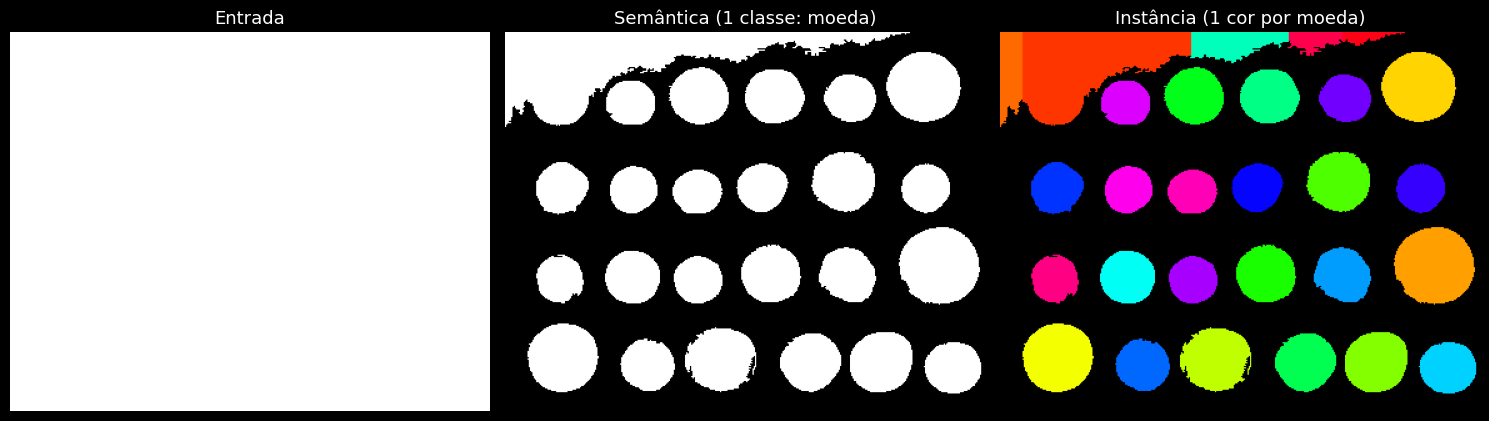

Instâncias encontradas na imagem 1: 28


In [ ]:
mascara_1, instancias_1 = segmentacao_por_instancia(
    imagem_1,
    tamanho_minimo=150,
    distancia_minima=18
)

plotar_comparacao(
    imagem_1,
    mascara_1,
    instancias_1,
    classe='moeda'
)

print(f'Instâncias encontradas na imagem 1: {instancias_1.max()}')

### Comparação da imagem 2

O mesmo teste é aplicado à segunda imagem do skimage.

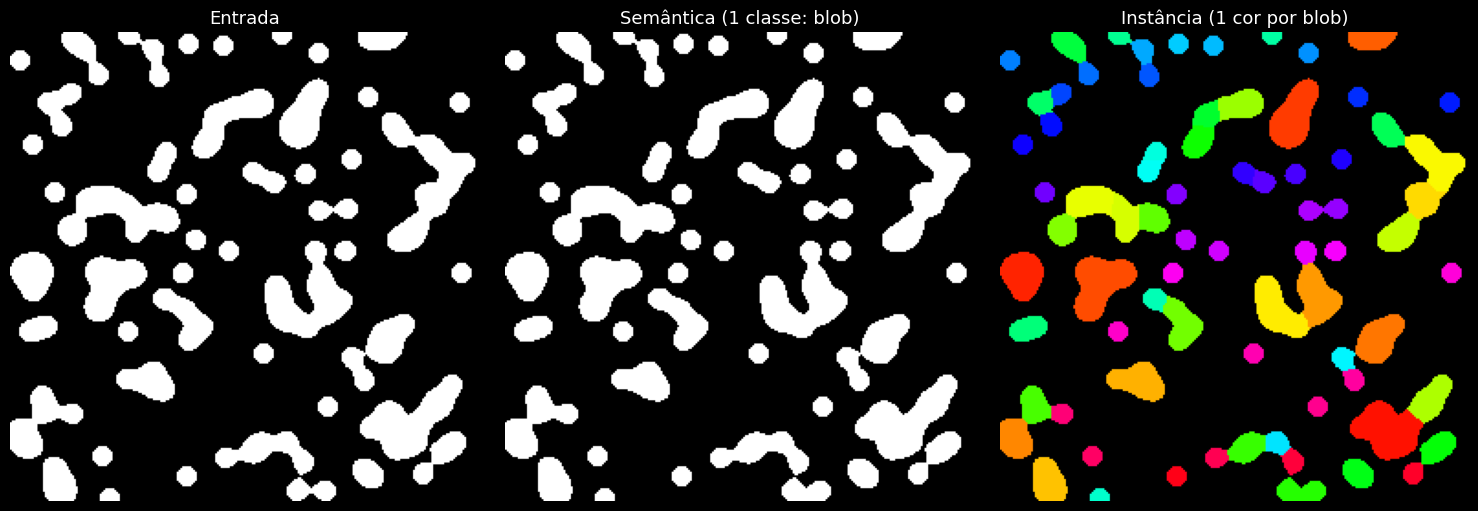

Instâncias encontradas na imagem 2: 76


In [ ]:
mascara_2, instancias_2 = segmentacao_por_instancia(
    imagem_2,
    tamanho_minimo=40,
    distancia_minima=8
)

plotar_comparacao(
    imagem_2,
    mascara_2,
    instancias_2,
    classe='blob'
)

print(f'Instâncias encontradas na imagem 2: {instancias_2.max()}')

### Análise

A segmentação semântica separa apenas o primeiro plano do fundo e, por isso, todos os objetos recebem a mesma classe. Já a segmentação por instância diferencia cada objeto individualmente. Na imagem de moedas, essa diferença é mais importante porque existem objetos próximos ou encostados; o watershed usa os centros detectados para tentar separá-los. Na imagem binary_blobs, os objetos são mais regulares e separados, então a segmentação por instância tende a produzir regiões individuais mais consistentes.